# Build the EpiSewer input from Covasim (shedding_hub curves already checked)

**Goal:** make everything `EpiSewer(data = ww_data, assumptions = ww_assumptions, shedding = model_shedding(load_per_case = ...))` needs.
Units: shedding is gc/mL of stool (shedding_hub label, reference event symptom onset: already checked); the load is gc/day; the concentration goes to EpiSewer in gc/mL; the flow in mL/day.

In [12]:
from pathlib import Path
import numpy as np
import pandas as pd
import covasim as cv

# Overview

**Goal:** make everything `EpiSewer(data = ww_data, assumptions = ww_assumptions, shedding = model_shedding(load_per_case = ...))` needs.
Units: shedding is gc/mL of stool (shedding_hub label, reference event symptom onset: already checked); the load is gc/day; the concentration goes to EpiSewer in gc/mL; the flow in mL/day.

## Settings
Epidemic: `N_AGENTS=50000`, `N_DAYS=180`, `TRANSMISSION_PROB_PER_CONTACT=0.012`, `N_INITIAL_INFECTIONS=10`, `FRIEND_COUNT_DISPERSION=None`, `INFECTIOUSNESS_DISPERSION=0.45`, `DAILY_TEST_PROB_IF_SYMPTOMATIC=0.1` (not used by EpiSewer; kept so the run matches run_covasim.py).
Maps for `pop_type='rank'`: `POPULATION_DENSITY_RASTER`, `ZIP_CODE_BOUNDARIES`, `SEWERSHED_BOUNDARIES` (same three files as run_covasim.py).

## Our assumptions
- `STOOL_ML_PER_PERSON_PER_DAY=128`: median fecal wet mass of 128 g per person per day, with 1 g taken as 1 mL [1]
- `SEWAGE_FLOW_LITRES_PER_PERSON_PER_DAY=270`: Point Loma treats 136 to 175 million gallons per day for about 2.2 million residents [2].
  - Calculation: 1 million gallons = 3.785 million L, so 136 MGD = 5.1 × 10⁸ L and 175 MGD = 6.6 × 10⁸ L per day.
  - Divided by 2.2 million residents this is 234 to 301 L per person per day. We use 270, the midpoint, rounded.
  - It is a per-resident average: the plant flow also includes commercial, industrial and infiltration water.
- `LAB_NOISE_CV=0.2`: placeholder lab noise (multiplicative, mean 1); no reference

## Technical settings
- `SHEDDING_PROFILE_DAYS=SHEDDING_PROFILE_DAYS=25`: days after infection kept when building the shedding distribution (check that the window holds about 100% of the shedding)
- A sample is taken every day (the best case)

## Steps
1. **Run Covasim** with the settings above. Copy `sim.shedding_lookup` after `initialize()` and before `run()`. Take `viral_shedding_hist` (agents × calendar days, gc/mL), `date_exposed`, `date_infectious` and `people.sewershed`.
2. **Check:** sliding each agent's curve (`shedding_lookup` row) to start at `date_infectious` reproduces `viral_shedding_hist`.
3. **Site load:** add up the agents (gc/mL), then × `STOOL_ML_PER_PERSON_PER_DAY` (128 mL), giving `load_gc_per_day`.
4. **Flow and concentration:** flow = agents × `SEWAGE_FLOW_LITRES_PER_PERSON_PER_DAY` (270 L). Concentration = load ÷ flow, in gc/L.
5. **Measurement:** concentration × lab noise (mean 1, CV 0.2). Leave out days with a concentration of 0.
6. **EpiSewer data tables:** concentration in gc/mL (÷ 1000) and flow in mL/day (× 1000). These are `ww_data`.
7. **Shedding distribution:** line each agent's shedding up by days since `date_exposed`, average over agents, and divide by the total (sums to 1). This is `shedding_dist`.
8. **Load per case:** mean total shedding of one infection × 128 mL, in gc per infection. This goes to `load_per_case_assume`.
9. **Generation time:** from `infection_log`, the infectee's infection day minus the infector's, from day 1. This is `generation_dist`.
10. **Save the CSVs** for the EpiSewer R script. For judging only: true infections per day from `infection_log`.
11. **Reported cases and delays for EpiNow2** (same simulation, so the two tools can be compared): `new_diagnoses`, and each agent's incubation and symptom-to-diagnosis delays.

## What each EpiSewer argument comes from
| EpiSewer argument | From step |
|---|---|
| `data` (`ww_data`: concentration, flow) | 3–6 |
| `shedding_dist`, `shedding_reference = "infection"` | 7 |
| `load_per_case` | 8 |
| `generation_dist` | 9 |
| not given to EpiSewer: true infections | 10 |
| EpiNow2: reported cases, delays, generation time, ascertainment | 11 (generation time from step 9) |

## References
1. Rose C, Parker A, Jefferson B, Cartmell E. The characterization of feces and urine: a review of the literature to inform advanced treatment technology. *Crit Rev Environ Sci Technol* 2015; 45:1827–1879. doi:10.1080/10643389.2014.1000761
2. City of San Diego. Point Loma Wastewater Treatment Plant fact sheet (about 175 MGD, more than 2.2 million residents); Point Loma annual reports 2014 (139.2 MGD) and 2016 (136.1 MGD).

## Epidemic

In [ ]:
# ---- The epidemic -------------------------------------------------------------------------------------------------
N_AGENTS                  = 50000      # number of simulated people
N_DAYS                    = 180        # length of the simulated epidemic, in days
TRANSMISSION_PROB_PER_CONTACT = 0.012  # Covasim's `beta`: chance of transmission per infectious contact (Covasim default is 0.016)
N_INITIAL_INFECTIONS      = 10         # agents infected on day 0 (the "seeds": infected by construction, not by anyone)
FRIEND_COUNT_DISPERSION   = None       # "k1": None = Poisson (the default), so it is not passed to Covasim below
INFECTIOUSNESS_DISPERSION = 0.45       # "k2": how uneven infectiousness is between people (superspreading)
DAILY_TEST_PROB_IF_SYMPTOMATIC = 0.1   # not used by EpiSewer; kept so the run matches run_covasim.py
SEED  = 1

## Wastewater Settings

In [39]:
# ---- Our assumptions and technical setting ---------------------------------------------------------------------------
STOOL_ML_PER_PERSON_PER_DAY           = 128    # Ref: Rose et al. 2015
SEWAGE_FLOW_LITRES_PER_PERSON_PER_DAY = 270    # Ref: Point Loma, City of San Diego
LAB_NOISE_CV                          = 0.2    # placeholder
SHEDDING_PROFILE_DAYS                 = 25

## Step 1. Run Covasim

In [13]:
def run_covasim(seed):
    testing = cv.test_prob(symp_prob=DAILY_TEST_PROB_IF_SYMPTOMATIC, asymp_prob=0.0, start_day=0)
    sim = cv.Sim(pop_type='rank', pop_size=N_AGENTS, pop_infected=N_INITIAL_INFECTIONS, n_imports=0,
                 beta=TRANSMISSION_PROB_PER_CONTACT, n_days=N_DAYS, rand_seed=seed, verbose=0,
                 beta_dist=dict(dist='neg_binomial', par1=1.0, par2=INFECTIOUSNESS_DISPERSION, step=0.01),
                 interventions=testing, density_raster=str(POPULATION_DENSITY_RASTER),
                 boundary_shapefile=str(ZIP_CODE_BOUNDARIES), sewershed_file=str(SEWERSHED_BOUNDARIES))
    sim.initialize(use_workers=True)
    shedding_lookup = np.array(sim.shedding_lookup).copy()     # copy now: Covasim redraws it after the run
    sim.run()
    return sim, shedding_lookup

sim, shedding_lookup = run_covasim(SEED)

/storage/hcraddock/GitHub/covasim4wastewater/covasim/population.py:67: RuntimeWarning: 
The boundary file has no "population" column, so regions are weighted by their area. Add a "population" column to weight by population (it is not needed when pop_type="rank" uses a density_raster).
  cvm.warn(


## Extract parameters from Covasim

In [14]:
viral_shedding_hist = np.asarray(sim.results['viral_shedding_hist'], dtype=float)   # agents x days, gc per mL of stool
date_exposed        = np.asarray(sim.people.date_exposed, dtype=float)               # day of infection (NaN = never)
date_infectious     = np.asarray(sim.people.date_infectious, dtype=float)            # day infectious (NaN = never)
sewershed_id        = np.asarray(sim.people.sewershed)                               # catchment of each agent
infection_log       = sim.people.infection_log                                       # every transmission: source, target, date
dates               = pd.to_datetime(sim.datevec)
n_days              = len(dates)

print('viral_shedding_hist:', viral_shedding_hist.shape, '| shedding_lookup:', shedding_lookup.shape, '| infections:', len(infection_log))

viral_shedding_hist: (50000, 181) | shedding_lookup: (50000, 180) | infections: 27217


## Step 2. Check: each agent's curve starts at `date_infectious`

In [15]:
# viral_shedding_hist should be each agent's shedding_lookup curve, placed so that it starts on date_infectious

agents_to_check = np.where(date_infectious <= n_days - 20)[0][:2000]       # agents who became infectious at least 20 days before the end

def hist_matches_curve(agent, days_after_date_infectious):
    start = int(date_infectious[agent]) + days_after_date_infectious
    first_15_days_in_hist  = viral_shedding_hist[agent, start : start + 15]    # what Covasim stored in viral_shedding_hist
    first_15_days_of_curve = shedding_lookup[agent, 0 : 15]                    # the agent's curve from shedding_hub
    return np.allclose(first_15_days_in_hist, first_15_days_of_curve, rtol=1e-4, atol=1e-3)

for days_after in (0, 1):
    matches = [hist_matches_curve(agent, days_after) for agent in agents_to_check]
    print(f'curve starts {days_after} day(s) after date_infectious: matches for {sum(matches)} of {len(matches)} agents')

curve starts 0 day(s) after date_infectious: matches for 2000 of 2000 agents
curve starts 1 day(s) after date_infectious: matches for 0 of 2000 agents


## Step 3. Site load: add up the agents, then × 128 mL of stool

In [18]:
# load_gc_per_day = sum over the agents in the site of viral_shedding_hist  x  128 mL of stool
def get_load_gc_per_day(agents_in_site):

    shedding_of_these_agents = viral_shedding_hist[agents_in_site]            # keep only the agents in the site (gc/mL)
    
    total_shedding_per_day = shedding_of_these_agents.sum(axis=0)             # add the agents up: one number per day (gc/mL)

    load_gc_per_day = total_shedding_per_day * STOOL_ML_PER_PERSON_PER_DAY    # x 128 mL of stool = gene copies per day
    
    return load_gc_per_day

In [16]:
# A "site" is the group of agents whose waste reaches one sampling point: everyone ('ALL'), or one sewershed.
# agents_in_site is a list of True / False with one entry per agent: True if that agent lives in the site.
sites = {'ALL': np.ones(N_AGENTS, dtype=bool)}
for sewershed_number, sewershed_name in sim.sewershed_labels.items():
    sites[sewershed_name] = (sewershed_id == sewershed_number)

In [19]:
load_gc_per_day = get_load_gc_per_day(sites['ALL'])

print({site_name: int(agents_in_site.sum()) for site_name, agents_in_site in sites.items()}, '(agents per site)')

print(f'ALL: peak load_gc_per_day = {load_gc_per_day.max():,.3e} gc/day')

{'ALL': 50000, 'Encina': 9155, 'Point Loma': 33862, 'South Bay': 2213} (agents per site)
ALL: peak load_gc_per_day = 1.597e+10 gc/day


## Step 4. Flow and concentration (gc/L)

In [21]:
# flow_L_per_day = agents in the site  x  270 L per person
# concentration  = load_gc_per_day / flow_L_per_day

def get_flow_L_per_day(agents_in_site):
    number_of_agents_in_site = agents_in_site.sum()                           # counts the True entries
    
    return number_of_agents_in_site * SEWAGE_FLOW_LITRES_PER_PERSON_PER_DAY   # litres per day

In [22]:
flow_L_per_day = get_flow_L_per_day(sites['ALL'])

concentration = load_gc_per_day / flow_L_per_day                              # gene copies per litre, no lab noise

print(f'ALL: flow_L_per_day = {flow_L_per_day:,} L/day | peak concentration = {concentration.max():,.1f} gc/L (no noise)')

ALL: flow_L_per_day = 13,500,000 L/day | peak concentration = 1,182.6 gc/L (no noise)


## Step 5. Measurement: concentration × lab noise (mean 1, sd 0.2)

In [23]:
# measurement = concentration  x  lab noise (mean 1, CV 0.2)

np.random.seed(SEED)          # so the random lab noise is the same every time the notebook is run

def add_lab_noise(concentration):
    lab_noise = np.random.normal(loc=1, scale=LAB_NOISE_CV, size=n_days)      # one random number near 1 for each day (mean 1, sd 0.2)
    return concentration * lab_noise

measurement = add_lab_noise(concentration)

peak_day = concentration.argmax()

print(f'peak day: concentration = {concentration[peak_day]:,.1f} gc/L, measurement = {measurement[peak_day]:,.1f} gc/L')

peak day: concentration = 1,182.6 gc/L, measurement = 1,388.1 gc/L


## Step 6. EpiSewer data: concentration (gc/mL) and flow (mL/day)

In [24]:
def build_site_table(site_name, agents_in_site):
    load_gc_per_day = get_load_gc_per_day(agents_in_site)
    
    flow_L_per_day = get_flow_L_per_day(agents_in_site)
    
    concentration = load_gc_per_day / flow_L_per_day
    
    measurement = add_lab_noise(concentration)

    infected_here = agents_in_site[infected_agent]                            # True for infections of agents who live in this site
    
    true_infections = np.bincount(infection_day[infected_here], minlength=n_days)[:n_days]    # infections on each day (the truth, only to judge)

    return pd.DataFrame({'site': site_name, 'date': dates, 'n_people': agents_in_site.sum(), 'true_infections': true_infections,
                         'load_gc_per_day': load_gc_per_day, 'flow_L_per_day': flow_L_per_day,
                         'concentration_true': concentration, 'concentration_noisy': measurement})

In [25]:
# One row per infection: who infected whom, and on which day (the seeds have no infector)
infections = pd.DataFrame(infection_log)

infected_agent = infections['target'].astype(int).to_numpy()

infection_day  = infections['date'].astype(int).to_numpy()

In [26]:
site_tables = []
for site_name, agents_in_site in sites.items():
    print(f'Building site table for {site_name} with {agents_in_site.sum()} agents')
    site_tables.append(build_site_table(site_name, agents_in_site))
ww_daily = pd.concat(site_tables, ignore_index=True)

Building site table for ALL with 50000 agents
Building site table for Encina with 9155 agents
Building site table for Point Loma with 33862 agents
Building site table for South Bay with 2213 agents


## Wastewater measurements

In [28]:
# ww_data, column 1: concentration. Covasim gives gc per litre, EpiSewer wants gc per mL, so divide by 1000.
# Days where the concentration is 0 (nothing shed yet) are left out.
has_signal = ww_daily['concentration_noisy'] > 0

ww_measurements = pd.DataFrame({'site': ww_daily['site'][has_signal], 'date': ww_daily['date'][has_signal],
                                'concentration': ww_daily['concentration_noisy'][has_signal] / 1000})
ww_measurements.head(3)

,site,date,concentration
4,ALL,2020-03-05,0.001377
5,ALL,2020-03-06,0.004941
6,ALL,2020-03-07,0.007730


### Wastewater flows

In [27]:
# ww_data, column 2: flow. Covasim gives litres per day, EpiSewer wants mL per day, so multiply by 1000.
ww_flows = pd.DataFrame({'site': ww_daily['site'], 'date': ww_daily['date'], 'flow': ww_daily['flow_L_per_day'] * 1000})

ww_flows.head(3)

,site,date,flow
0,ALL,2020-03-01,13500000000
1,ALL,2020-03-02,13500000000
2,ALL,2020-03-03,13500000000


## Step 7. Shedding distribution: share of one infection's shedding on each day after `date_exposed`

In [29]:
n_days

181

In [30]:
SHEDDING_PROFILE_DAYS

40

### Shedding Distribution

In [34]:
21/(14+21)

0.6

In [40]:
# =====================================================================================================================
# GOAL
# shedding_dist answers one question: for ONE infection, what share of its total shedding happens on
# day 0, day 1, day 2, ... day 39 after the person was infected?   (day 0 = the day of infection)
# EpiSewer needs this to know how infections today turn into virus in the wastewater over the following days.
#
# PROBLEM
# viral_shedding_hist is organised by CALENDAR day (column 0 = the first day of the simulation).
# Every agent is infected on a different calendar day, so their shedding curves are shifted against each other.
#
# FIX
# For each agent, cut out the SHEDDING_PROFILE_DAYS=25 days that start on THEIR OWN infection day. 
# Now every cut-out starts at "day 0 after
# infection". Add all the cut-outs up, then divide by the total so the SHEDDING_PROFILE_DAYS=25 numbers become shares that sum to 1.
#
# TINY EXAMPLE (3 agents, 4 days instead of SHEDDING_PROFILE_DAYS=25)
#   agent A, infected on calendar day 0:  cut-out = [0,  0,  6, 4]
#   agent B, infected on calendar day 2:  cut-out = [0,  0, 12, 8]
#   agent C, infected on calendar day 3:  cut-out = [0,  0,  3, 2]
#   added up                                       = [0,  0, 21, 14]      (total = 35)
#   divided by the total  -> shedding_dist         = [0,  0, 0.6, 0.4]  #21/(14+21) = 0.6 14/(14+21) = 0.4
#   meaning: 60% of an infection's shedding happens on day 2 after infection, SHEDDING_PROFILE_DAYS=25% on day 3.
#   (We ADD the agents instead of averaging them: after dividing by the total, the result is exactly the same.)
# =====================================================================================================================


# ---------------------------------------------------------------------------------------------------------------------
# STEP 1. Choose which agents to use. We leave out two kinds of agents:
#   (a) agents infected MORE than once: their row in viral_shedding_hist mixes two infections, so we cannot tell which
#       shedding belongs to which infection
#   (b) agents infected too late: we need SHEDDING_PROFILE_DAYS=25 full days after infection, but the simulation ends before those SHEDDING_PROFILE_DAYS=25 days are over
# ---------------------------------------------------------------------------------------------------------------------

# How many times does each agent appear as "infected" in infection_log?  One number per agent:
# 0 = never infected, 1 = infected once, 2 = infected twice, ...
n_infections_per_agent = np.bincount(infected_agent, minlength=N_AGENTS)

# True for the agents who were infected exactly once
infected_once = (n_infections_per_agent == 1)

# True for the agents infected on or before day (n_days - SHEDDING_PROFILE_DAYS=25), so that their SHEDDING_PROFILE_DAYS=25 days fit inside the run.
# Agents who were never infected have date_exposed = NaN, and NaN <= anything is False, so they are left out automatically.
infected_early_enough = (date_exposed <= n_days - SHEDDING_PROFILE_DAYS)

# Keep the agents where BOTH are True. np.where(...)[0] turns the True/False list into the agent numbers, e.g. [4, 17, 23, ...]
agents_used = np.where(infected_once & infected_early_enough)[0]

# ---------------------------------------------------------------------------------------------------------------------
# STEP 2. For each agent, cut out the SHEDDING_PROFILE_DAYS=25 days that start on THEIR OWN infection day, and add the cut-out to a running total.
# ---------------------------------------------------------------------------------------------------------------------

# SHEDDING_PROFILE_DAYS=25 empty boxes, one for each day after infection (day 0, day 1, ... day 39). All start at 0 and collect the running total.
shedding_by_day_since_infection = np.zeros(SHEDDING_PROFILE_DAYS)

for agent in agents_used:
    # The calendar day this agent was infected, for example day 57
    day_infected = int(date_exposed[agent])

    # This agent's row of viral_shedding_hist, cut from their infection day to SHEDDING_PROFILE_DAYS=25 days later (calendar days 57 to 96).
    # The += adds these SHEDDING_PROFILE_DAYS=25 numbers into the SHEDDING_PROFILE_DAYS=25 boxes, box by box: the first number goes into the day-0 box, the next
    # into the day-1 box, and so on. Because every agent is cut out from their own infection day, the boxes line up.
    shedding_by_day_since_infection += viral_shedding_hist[agent, day_infected : day_infected + SHEDDING_PROFILE_DAYS]

# After the loop, shedding_by_day_since_infection[0] = the shedding of all these agents ON their infection day (gc/mL, added up),
# [1] = the shedding one day later, and so on.


# ---------------------------------------------------------------------------------------------------------------------


In [41]:
shedding_by_day_since_infection

array([0.00000000e+00, 8.28611680e+05, 7.87401723e+07, 4.42973649e+08,
       8.95240143e+08, 1.10591103e+09, 1.07620994e+09, 8.93925606e+08,
       6.75613977e+08, 4.79660393e+08, 3.24269933e+08, 2.13377093e+08,
       1.36872143e+08, 8.66983734e+07, 5.42753224e+07, 3.37496963e+07,
       2.07477103e+07, 1.26640656e+07, 7.68865077e+06, 4.64863937e+06,
       2.80147357e+06, 1.68394664e+06, 1.01014718e+06, 6.04983099e+05,
       3.61874082e+05])

In [42]:
# STEP 3. Turn the totals into shares. Divide every box by the grand total, so the SHEDDING_PROFILE_DAYS=25 numbers add up to 1.
# This is the shedding_dist that EpiSewer gets (it has no unit: each number is a share of the total).
# ---------------------------------------------------------------------------------------------------------------------
shedding_dist = shedding_by_day_since_infection / shedding_by_day_since_infection.sum()

shedding_dist

array([0.00000000e+00, 1.26494832e-04, 1.20203771e-02, 6.76238082e-02,
       1.36666251e-01, 1.68827007e-01, 1.64292875e-01, 1.36465575e-01,
       1.03138392e-01, 7.32243610e-02, 4.95026460e-02, 3.25738825e-02,
       2.08947316e-02, 1.32352662e-02, 8.28560344e-03, 5.15218680e-03,
       3.16731973e-03, 1.93328056e-03, 1.17373990e-03, 7.09655525e-04,
       4.27669482e-04, 2.57069206e-04, 1.54207817e-04, 9.23559699e-05,
       5.52432488e-05])

In [43]:
# ---------------------------------------------------------------------------------------------------------------------
# CHECK. The SHEDDING_PROFILE_DAYS=25 days should hold about 100% of these agents' shedding.
#   viral_shedding_hist[agents_used].sum()          = ALL the shedding of these agents over the whole run
#   shedding_by_day_since_infection.sum()           = the part of it that falls inside the 40 days after infection
# If the share is much lower than 100%, the agents keep shedding after day 40: raise SHEDDING_PROFILE_DAYS.
# ---------------------------------------------------------------------------------------------------------------------
share_inside_window = shedding_by_day_since_infection.sum() / viral_shedding_hist[agents_used].sum()
print(f'{len(agents_used):,} agents used | the {SHEDDING_PROFILE_DAYS} days hold {share_inside_window:.1%} of their shedding | shedding_dist sums to {shedding_dist.sum():.3f}')

19,380 agents used | the 25 days hold 100.0% of their shedding | shedding_dist sums to 1.000


### Check to see shedidng distribution

In [38]:
# What share of one infection's shedding falls inside the first N days after infection?
cumulative_share = np.cumsum(shedding_dist)                    # share inside the first 1 day, 2 days, 3 days ...
for days in (10, 15, 20, 25, 30, 40):
    print(f'first {days} days after infection hold {cumulative_share[days - 1]:.2%} of the shedding')

# How many days pass between infection and the start of shedding?
print('mean days from infection to date_infectious:', np.nanmean(date_infectious - date_exposed).round(1))

first 10 days after infection hold 86.20% of the shedding
first 15 days after infection hold 98.67% of the shedding
first 20 days after infection hold 99.89% of the shedding
first 25 days after infection hold 99.99% of the shedding
first 30 days after infection hold 100.00% of the shedding
first 40 days after infection hold 100.00% of the shedding
mean days from infection to date_infectious: 4.5


### Plot

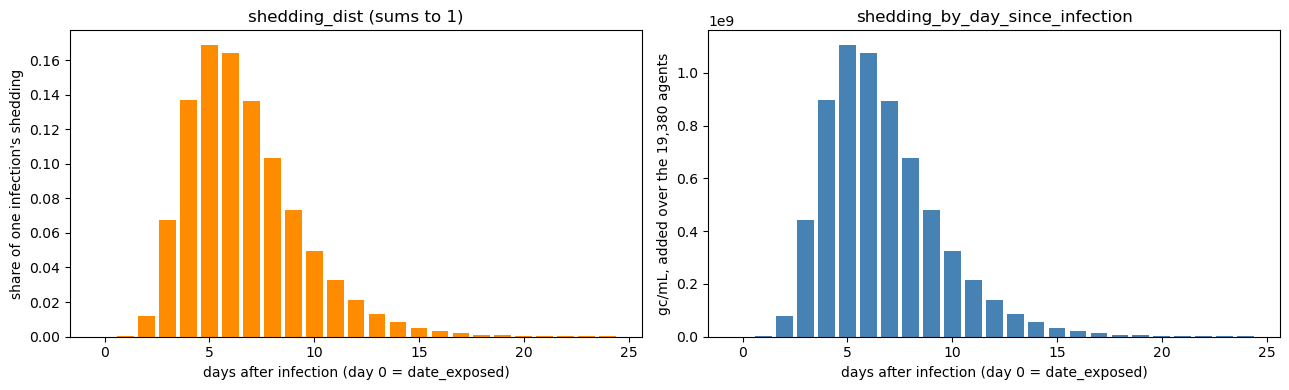

In [48]:
import matplotlib.pyplot as plt

days_after_infection = np.arange(SHEDDING_PROFILE_DAYS)        # 0, 1, 2 ... the x axis

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4))

# Right: shedding_dist = the same numbers divided by their total, so they sum to 1
left.bar(days_after_infection, shedding_dist, color='darkorange')
left.set_title('shedding_dist (sums to 1)')
left.set_xlabel('days after infection (day 0 = date_exposed)')
left.set_ylabel("share of one infection's shedding")

# Left: shedding_by_day_since_infection = the shedding of all the agents used, added up, on each day after infection
right.bar(days_after_infection, shedding_by_day_since_infection, color='steelblue')
right.set_title('shedding_by_day_since_infection')
right.set_xlabel('days after infection (day 0 = date_exposed)')
right.set_ylabel(f'gc/mL, added over the {len(agents_used):,} agents')

plt.tight_layout()
plt.show()

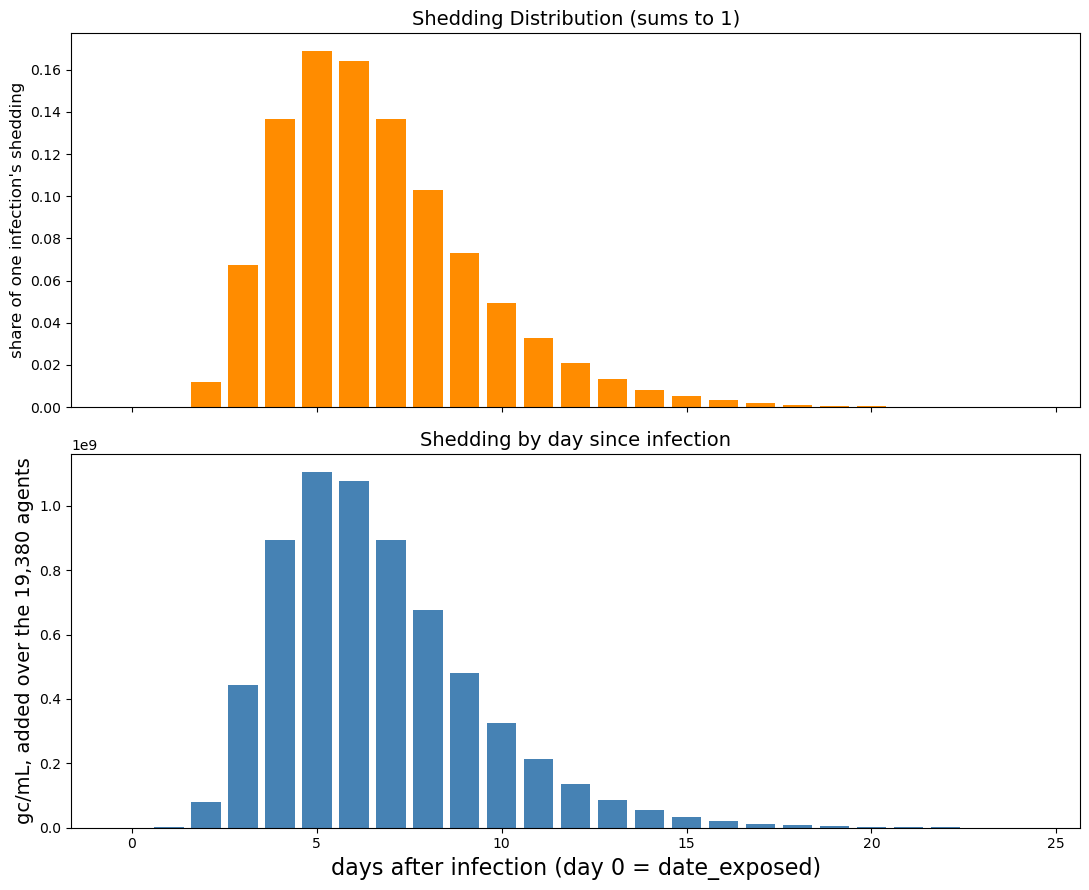

In [54]:
import matplotlib.pyplot as plt

days_after_infection = np.arange(SHEDDING_PROFILE_DAYS)        # 0, 1, 2 ... the x axis

fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 9), sharex=True)      # two plots stacked, sharing the same x axis

# Top: shedding_dist = the same numbers divided by their total, so they sum to 1
top.bar(days_after_infection, shedding_dist, color='darkorange')
top.set_title('Shedding Distribution (sums to 1)', fontsize=14)
top.set_ylabel("share of one infection's shedding", fontsize=12)

# Bottom: shedding_by_day_since_infection = the shedding of all the agents used, added up, on each day after infection
bottom.bar(days_after_infection, shedding_by_day_since_infection, color='steelblue')
bottom.set_title('Shedding by day since infection', fontsize=14)
bottom.set_ylabel(f'gc/mL, added over the {len(agents_used):,} agents', fontsize=14)
bottom.set_xlabel('days after infection (day 0 = date_exposed)', fontsize=16)

plt.tight_layout()
plt.show()

## Step 8. Load per case: total shedding of one infection × 128 mL of stool

In [44]:
# load_per_case = total shedding of one infection  x  128 mL of stool

total_shedding_of_all_agents = shedding_by_day_since_infection.sum()              # gc/mL, added over the days and over the agents

total_shedding_of_one_infection = total_shedding_of_all_agents / len(agents_used)  # gc/mL, the average for one agent

load_per_case = total_shedding_of_one_infection * STOOL_ML_PER_PERSON_PER_DAY      # x 128 mL of stool = gene copies per infection

print(f'load_per_case = {load_per_case:,.3e} gene copies per infection')

load_per_case = 4.326e+07 gene copies per infection


## Step 9. Generation time: infectee's infection day minus the infector's

### - Infector: 'Target' date, 
### - Infectee: 'Soucre' date

In [45]:
# generation_dist = infection day of the infectee  minus  infection day of the infector  (from infection_log)

# Every transmission: infector ("source"), infectee ("target") and the day of the transmission. The seeds have no infector.
transmissions = infections[['source', 'target', 'date']].dropna(subset=['source']).copy()

transmissions['source'] = transmissions['source'].astype(int)

#TARGET DATE GIVES INFECTIONS
# Every infection of every agent. An agent can be infected more than once, so this is a list of (agent, infection day).
agent_infection_days = infections[['target', 'date']].rename(columns={'target': 'source', 'date': 'source_infection_day'})

# For each transmission, look up the infector's latest infection on or before the day of the transmission
transmissions = pd.merge_asof(transmissions.sort_values('date'), agent_infection_days.sort_values('source_infection_day'),
                              left_on='date', right_on='source_infection_day', by='source')

transmissions['generation_time'] = transmissions['date'] - transmissions['source_infection_day']

generation_days = transmissions['generation_time'].dropna().astype(int)

counts_by_day = np.bincount(generation_days)[1:]                                   # how many transmissions took 1, 2, 3 ... days

generation_dist = counts_by_day / counts_by_day.sum()                              # sums to 1

print(f'{len(transmissions):,} transmissions | mean generation time {generation_days.mean():.2f} days | days 1 to {len(generation_dist)}')

27,207 transmissions | mean generation time 7.39 days | days 1 to 55


## Step 10. Save the CSVs for the R script

In [49]:
OUTPUT_FOLDER = Path('data_ww_case_deconvolution')

In [50]:
print(OUTPUT_FOLDER.resolve())      # the full path of the folder

/storage/hcraddock/GitHub/covasim4wastewater/network_rank_model/models_deconvolution/data_ww_case_deconvolution


## Episewer outputs

In [56]:
ww_measurements.head(5)

,site,date,concentration
4,ALL,2020-03-05,0.001377
5,ALL,2020-03-06,0.004941
6,ALL,2020-03-07,0.007730
7,ALL,2020-03-08,0.007923
8,ALL,2020-03-09,0.005513


In [57]:
ww_flows.head(5)

,site,date,flow
0,ALL,2020-03-01,13500000000
1,ALL,2020-03-02,13500000000
2,ALL,2020-03-03,13500000000
3,ALL,2020-03-04,13500000000
4,ALL,2020-03-05,13500000000


In [58]:
ww_daily.head(5)

,site,date,n_people,true_infections,load_gc_per_day,flow_L_per_day,concentration_true,concentration_noisy
0,ALL,2020-03-01,50000,10,0.0,13500000,0.00000,0.000000
1,ALL,2020-03-02,50000,0,0.0,13500000,0.00000,0.000000
2,ALL,2020-03-03,50000,0,0.0,13500000,0.00000,0.000000
3,ALL,2020-03-04,50000,0,0.0,13500000,0.00000,0.000000
4,ALL,2020-03-05,50000,1,21203907.0,13500000,1.57066,1.376727


In [59]:
# For EpiSewer

#Measurement
ww_measurements.to_csv(OUTPUT_FOLDER / 'ww_data_measurements.csv', index=False)        # ww_data, column 1: concentration (gc/mL)

#Flows
ww_flows.to_csv(OUTPUT_FOLDER / 'ww_data_flows.csv', index=False)                       # ww_data, column 2: flow (mL/day)

# Only used to judge the result (never given to EpiSewer)
ww_daily.to_csv(OUTPUT_FOLDER / 'covasim_ww_daily.csv', index=False)

In [61]:
# shedding_dist as a table: one row per day after infection
shedding_dist_table = pd.DataFrame({
    'day': np.arange(SHEDDING_PROFILE_DAYS),     # days after infection: 0, 1, 2 ...
    'pmf': shedding_dist})                        # share of one infection's shedding on that day (sums to 1)

shedding_dist_table.head()                        # look at it before saving

shedding_dist_table.to_csv(OUTPUT_FOLDER / 'covasim_ww_shedding_dist.csv', index=False)

In [60]:
transmissions.to_csv(OUTPUT_FOLDER / 'covasim_transmission.csv', index=False)           # generation_dist is built from generation_time

In [62]:
# Save log: the settings and the load per case
log_table = pd.DataFrame({
    'seed': [SEED],
    'LOAD_PER_CASE': [load_per_case],                                    # gene copies per infection (read by the R script)
    'WW_STOOL_ML_PER_DAY': [STOOL_ML_PER_PERSON_PER_DAY],
    'WW_FLOW_PER_PERSON': [SEWAGE_FLOW_LITRES_PER_PERSON_PER_DAY],
    'WW_NOISE_CV': [LAB_NOISE_CV]})

log_table                                                                # look at it before saving

log_table.to_csv(OUTPUT_FOLDER / 'covasim_run_info.csv', index=False)

In [63]:
log_table

,seed,LOAD_PER_CASE,WW_STOOL_ML_PER_DAY,WW_FLOW_PER_PERSON,WW_NOISE_CV
0,1,4.326478e+07,128,270,0.2


In [ ]:
print(sorted(path.name for path in OUTPUT_FOLDER.glob('*.csv')))

## Step 11. Reported cases and delays for EpiNow2 (same simulation as EpiSewer)

In [64]:
# Reported cases: the only data EpiNow2 is given. true_infections is the same truth as for EpiSewer.
cases = pd.DataFrame({
    'date': dates,
    'day': np.arange(n_days),
    'confirm': np.array(sim.results['new_diagnoses'].values).astype(int),                            # agents diagnosed on each day
    'true_infections': ww_daily.loc[ww_daily['site'] == 'ALL', 'true_infections'].to_numpy(),
    'r_eff': np.array(sim.results['r_eff'].values)})                                                  # Covasim's own Rt, only to judge Rt

# Delays: one row per agent who was ever infected. EpiNow2 uses the incubation and the symptom-to-diagnosis delay.
delays = pd.DataFrame({
    'uid': np.arange(N_AGENTS),
    'date_exposed': date_exposed,
    'date_infectious': date_infectious,
    'date_symptomatic': np.asarray(sim.people.date_symptomatic, dtype=float),
    'date_tested': np.asarray(sim.people.date_tested, dtype=float),
    'date_diagnosed': np.asarray(sim.people.date_diagnosed, dtype=float)})
delays['delay_latent'] = delays['date_infectious'] - delays['date_exposed']
delays['delay_incubation'] = delays['date_symptomatic'] - delays['date_exposed']
delays['delay_symptom_to_diagnosis'] = delays['date_diagnosed'] - delays['date_symptomatic']
delays['delay_infection_to_diagnosis'] = delays['date_diagnosed'] - delays['date_exposed']
delays = delays.dropna(subset=['date_exposed'])                                                       # only agents who were ever infected

In [65]:
cases.to_csv(OUTPUT_FOLDER / 'covasim_cases.csv', index=False)
delays.to_csv(OUTPUT_FOLDER / 'covasim_delays.csv', index=False)

print(f"reported cases: {cases['confirm'].sum():,} of {cases['true_infections'].sum():,} infections (ascertainment {cases['confirm'].sum() / cases['true_infections'].sum():.2f})")
print(sorted(path.name for path in OUTPUT_FOLDER.glob('*.csv')))

reported cases: 10,222 of 27,217 infections (ascertainment 0.38)
['covasim_cases.csv', 'covasim_delays.csv', 'covasim_run_info.csv', 'covasim_transmission.csv', 'covasim_ww_daily.csv', 'covasim_ww_shedding_dist.csv', 'ww_data_flows.csv', 'ww_data_measurements.csv']
